# 02 — Chuẩn bị giao dịch và khai phá Apriori

## Mục tiêu
Tìm các tổ hợp đặc điểm đi cùng **Churn=Yes**, không xây dựng mô hình dự đoán. Mỗi khách hàng là một giao dịch gồm các mục dạng `Tên biến=Giá trị`.

**Điều kiện:** chạy Notebook 1 trước. Notebook này kiểm tra dấu vân tay SHA256 của bảng sạch và nguồn gốc để không sử dụng nhầm dữ liệu. Chạy độc lập bằng Restart Kernel → Run All; không cần biến của Notebook 1 trong bộ nhớ.

**Phạm vi:** 14 biến đầu vào (12 biến phân loại và 2 biến chia nhóm), thêm Churn. Toàn bộ khách hàng được dùng, không SMOTE, không train/test, không mô hình ML dự đoán.

**Tài liệu:** [Apriori — mlxtend](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/), [Association rules — mlxtend](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/). Apriori tìm tập mục phổ biến; bước sinh luật là bước tiếp theo, không phải bản thân thuật toán dự đoán churn.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules
from IPython.display import display, Markdown

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv").is_file()), None)
assert ROOT is not None, "Hãy mở notebook bên trong dự án."
DATA_DIR = ROOT / "data/processed/apriori"
TABLE_DIR = ROOT / "reports/apriori/tables"
FIG_DIR = ROOT / "reports/apriori/figures"
for directory in [TABLE_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
clean_path = DATA_DIR / "telco_clean.csv"
metadata = json.loads((DATA_DIR / "cleaning_metadata.json").read_text(encoding="utf-8"))
assert hashlib.sha256(clean_path.read_bytes()).hexdigest() == metadata["clean_sha256"], "Chạy lại Notebook 1."
assert hashlib.sha256((ROOT / metadata["source"]).read_bytes()).hexdigest() == metadata["source_sha256"]
clean = pd.read_csv(clean_path)
assert clean.shape == (metadata["rows"], metadata["columns"])
assert not clean.isna().any().any()
assert clean["Churn"].value_counts().to_dict() == metadata["churn_counts"]
N = len(clean)
base_rate = clean["Churn"].eq("Yes").mean()
SUPPORTS = [0.05, 0.10]
MIN_CONFIDENCE = 0.40
MIN_LIFT = 1.50
MAX_ANTECEDENTS = 3
REDUNDANCY_DELTA = 0.02  # 2 điểm phần trăm, không phải 2% tương đối
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})
print(f"{N:,} khách; churn nền = {base_rate:.4%}; mlxtend {mlxtend.__version__}")

7,043 khách; churn nền = 26.5370%; mlxtend 0.25.0


## 1. Rời rạc hóa và chọn biến

- Tenure: 0–12, 13–24, 25–48, >48 tháng; kiểm tra các điểm biên.
- Phí tháng: chia theo phân vị 1/3 và 2/3 **không dùng Churn để chọn mốc**. Các nhóm có thể không bằng nhau tuyệt đối khi nhiều khách có cùng mức phí.
- Lưu mốc dưới dạng số đầy đủ. Khi hiển thị có làm tròn, phép chia nhóm vẫn dùng số chưa làm tròn.
- Không đưa customerID, TotalCharges, số tenure/phí gốc vào giao dịch. Loại TotalCharges là lựa chọn giới hạn phạm vi vì có thông tin chồng lấn, không khẳng định nó hoàn toàn tương đương hai biến kia.
- Giữ riêng No và No internet service; không biến chúng thành dữ liệu thiếu.

In [2]:
CATEGORICAL = ["Contract", "InternetService", "TechSupport", "OnlineSecurity",
               "OnlineBackup", "DeviceProtection", "StreamingTV", "PaymentMethod",
               "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]
TENURE_LABELS = ["0-12", "13-24", "25-48", ">48"]
CHARGE_LABELS = ["Low", "Medium", "High"]
assert clean["tenure"].between(0, 72).all() and (clean["tenure"] % 1 == 0).all()
transactions = clean[CATEGORICAL].copy()
transactions["TenureGroup"] = pd.cut(
    clean["tenure"], [-np.inf, 12, 24, 48, np.inf], labels=TENURE_LABELS).astype(str)
charge_groups, charge_edges = pd.qcut(
    clean["MonthlyCharges"], q=3, labels=CHARGE_LABELS, retbins=True, duplicates="raise")
transactions["MonthlyChargesGroup"] = charge_groups.astype(str)
transactions["Churn"] = clean["Churn"]
assert transactions.shape == (N, 15)
assert not transactions.isna().any().any()
boundary_check = pd.cut(pd.Series([0, 12, 13, 24, 25, 48, 49, 72]),
                        [-np.inf, 12, 24, 48, np.inf], labels=TENURE_LABELS).astype(str)
assert boundary_check.tolist() == ["0-12", "0-12", "13-24", "13-24", "25-48", "25-48", ">48", ">48"]
charge_boundary_check = pd.cut(pd.Series(charge_edges), charge_edges,
                               labels=CHARGE_LABELS, include_lowest=True).astype(str)
assert charge_boundary_check.tolist() == ["Low", "Low", "Medium", "High"]
binning = {
    "tenure": {"labels": TENURE_LABELS, "upper_bounds": [12, 24, 48, None]},
    "monthly_charges": {"method": "qcut; quantiles 0, 1/3, 2/3, 1",
                        "edges": charge_edges.tolist(), "labels": CHARGE_LABELS,
                        "intervals": "[min,q1], (q1,q2], (q2,max]"},
}
print("Mốc phí tháng (đầy đủ):", charge_edges.tolist())
display(pd.DataFrame({
    "group": CHARGE_LABELS, "lower": charge_edges[:-1], "upper": charge_edges[1:],
    "interval": ["[lower, upper]", "(lower, upper]", "(lower, upper]"],
    "n_customers": charge_groups.value_counts(sort=False).to_numpy(),
}))
display(transactions.head())
(DATA_DIR / "binning_metadata.json").write_text(
    json.dumps(binning, ensure_ascii=False, indent=2), encoding="utf-8")

Mốc phí tháng (đầy đủ): [18.25, 50.4, 83.9, 118.75]


,group,lower,upper,interval,n_customers
0,Low,18.25,50.40,"[lower, upper]",2351
1,Medium,50.40,83.90,"(lower, upper]",2345
2,High,83.90,118.75,"(lower, upper]",2347


,Contract,InternetService,TechSupport,OnlineSecurity,OnlineBackup,DeviceProtection,StreamingTV,PaymentMethod,PaperlessBilling,SeniorCitizen,Partner,Dependents,TenureGroup,MonthlyChargesGroup,Churn
0,Month-to-month,DSL,No,No,Yes,No,No,Electronic check,Yes,No,Yes,No,0-12,Low,No
1,One year,DSL,No,Yes,No,Yes,No,Mailed check,No,No,No,No,25-48,Medium,No
2,Month-to-month,DSL,No,Yes,Yes,No,No,Mailed check,Yes,No,No,No,0-12,Medium,Yes
3,One year,DSL,Yes,Yes,No,Yes,No,Bank transfer (automatic),No,No,No,No,25-48,Low,No
4,Month-to-month,Fiber optic,No,No,No,No,No,Electronic check,Yes,No,No,No,0-12,Medium,Yes


429

## 2. Ma trận giao dịch Boolean

Mỗi cột là một mục, ví dụ `Contract=Month-to-month`; True nghĩa là khách hàng có đặc điểm đó. Không dùng `drop_first`, vì cần biểu diễn đầy đủ mọi trạng thái. Churn được đưa vào để khai phá **quan hệ đồng xuất hiện**, không phải đưa đáp án vào mô hình dự đoán.

Mỗi dòng phải có đúng 15 mục True: một mục cho mỗi biến. Không lọc chỉ khách churn trước khi chạy.

In [3]:
encoded = pd.get_dummies(transactions, columns=list(transactions.columns),
                         prefix_sep="=", dtype=bool)
assert encoded.columns.is_unique
assert encoded.dtypes.eq(bool).all()
assert encoded.sum(axis=1).eq(15).all()
for column in transactions:
    items = [c for c in encoded if c.startswith(column + "=")]
    assert encoded[items].sum(axis=1).eq(1).all()
assert np.isclose(encoded["Churn=Yes"].mean(), base_rate)
display(encoded.head())
print("Kích thước ma trận:", encoded.shape)
print("Giao dịch đầu tiên:", encoded.columns[encoded.iloc[0]].tolist())
transactions.to_csv(DATA_DIR / "transactions_categorical.csv", index=False, encoding="utf-8-sig")
encoded.to_csv(DATA_DIR / "transactions_boolean.csv", index=False, encoding="utf-8-sig")

,Contract=Month-to-month,Contract=One year,Contract=Two year,InternetService=DSL,InternetService=Fiber optic,InternetService=No,TechSupport=No,TechSupport=No internet service,TechSupport=Yes,OnlineSecurity=No,...,Dependents=Yes,TenureGroup=0-12,TenureGroup=13-24,TenureGroup=25-48,TenureGroup=>48,MonthlyChargesGroup=High,MonthlyChargesGroup=Low,MonthlyChargesGroup=Medium,Churn=No,Churn=Yes
0,True,False,False,True,False,False,True,False,False,True,...,False,True,False,False,False,False,True,False,True,False
1,False,True,False,True,False,False,True,False,False,False,...,False,False,False,True,False,False,False,True,True,False
2,True,False,False,True,False,False,True,False,False,False,...,False,True,False,False,False,False,False,True,False,True
3,False,True,False,True,False,False,False,False,True,False,...,False,False,False,True,False,False,True,False,True,False
4,True,False,False,False,True,False,True,False,False,True,...,False,True,False,False,False,False,False,True,False,True


Kích thước ma trận: (7043, 42)
Giao dịch đầu tiên: ['Contract=Month-to-month', 'InternetService=DSL', 'TechSupport=No', 'OnlineSecurity=No', 'OnlineBackup=Yes', 'DeviceProtection=No', 'StreamingTV=No', 'PaymentMethod=Electronic check', 'PaperlessBilling=Yes', 'SeniorCitizen=No', 'Partner=Yes', 'Dependents=No', 'TenureGroup=0-12', 'MonthlyChargesGroup=Low', 'Churn=No']


## 3. Apriori và ba chỉ số

Với luật A → Churn=Yes:
- **Support** = số khách có cả A và churn / tổng số khách.
- **Confidence** = số khách có cả A và churn / số khách có A.
- **Lift** = confidence / tỷ lệ churn chung.

Nguyên lý Apriori: một tập mục không phổ biến thì mọi tập lớn hơn chứa nó cũng không phổ biến. Ví dụ nếu A xuất hiện ít hơn ngưỡng, A kết hợp B không thể xuất hiện nhiều hơn A.

Ngưỡng khởi đầu: support ≥ 0,05, confidence ≥ 0,40, lift ≥ 1,5. Đây là lựa chọn thực nghiệm để có nhóm đủ lớn và tỷ lệ churn cao hơn nền, không phải kiểm định ý nghĩa thống kê. Với churn nền khoảng 26,5%, confidence 40% và lift 1,5 gần nhau.

Giới hạn tập mục 4 mục = tối đa 3 điều kiện ở tiền đề + 1 mục hệ quả. Dùng chế độ tiết kiệm bộ nhớ của Apriori. Lưu mọi luật mục tiêu đạt support trước khi lọc confidence/lift; không xóa bằng chứng.

In [4]:
METRICS = ["antecedent support", "consequent support", "support", "confidence", "lift"]
def mine_rules(frame, min_support):
    started = time.perf_counter()
    itemsets = apriori(frame, min_support=min_support, use_colnames=True,
                      max_len=MAX_ANTECEDENTS + 1, low_memory=True)
    if itemsets.empty:
        return itemsets, pd.DataFrame(columns=["antecedents", "consequents"] + METRICS), time.perf_counter()-started
    rules = association_rules(itemsets, num_itemsets=len(frame), metric="confidence",
                              min_threshold=0.0, return_metrics=METRICS)
    target_mask = (
        rules["consequents"].map(lambda s: s == frozenset({"Churn=Yes"}))
        & rules["antecedents"].map(lambda s: 1 <= len(s) <= MAX_ANTECEDENTS
                                  and not any(x.startswith("Churn=") for x in s))
    )
    return itemsets, rules.loc[target_mask].copy().reset_index(drop=True), time.perf_counter()-started

# Kiểm tra bằng giao dịch nhỏ trước khi chạy dữ liệu thật: 2/4, 2/3, (2/3)/(3/4).
toy = pd.DataFrame({"A=Yes": [True, True, True, False],
                    "Churn=Yes": [True, True, False, True],
                    "Churn=No": [False, False, True, False]})
_, toy_rules, _ = mine_rules(toy, .25)
toy_rule = toy_rules.loc[toy_rules["antecedents"].map(lambda s: s == frozenset({"A=Yes"}))].iloc[0]
assert np.allclose(toy_rule[["support", "confidence", "lift"]].to_numpy(dtype=float),
                   [.5, 2/3, (2/3)/(.75)])
_, empty_rules, _ = mine_rules(toy, 1.0)
assert empty_rules.empty

itemsets_05, target_05, seconds_05 = mine_rules(encoded, SUPPORTS[0])
print(f"Tập mục: {len(itemsets_05):,}; luật mục tiêu trước lọc: {len(target_05):,}; {seconds_05:.2f} giây")
display(target_05[["antecedents", "support", "confidence", "lift"]].head(10))

Tập mục: 11,604; luật mục tiêu trước lọc: 659; 1.01 giây


,antecedents,support,confidence,lift
0,frozenset({Contract=Month-to-month}),0.234985,0.427097,1.609440
1,frozenset({InternetService=DSL}),0.065171,0.189591,0.714441
2,frozenset({InternetService=Fiber optic}),0.184154,0.418928,1.578656
3,frozenset({TechSupport=No}),0.205310,0.416355,1.568960
4,frozenset({OnlineSecurity=No}),0.207440,0.417667,1.573906
5,frozenset({OnlineBackup=No}),0.175067,0.399288,1.504645
6,frozenset({OnlineBackup=Yes}),0.074258,0.215315,0.811377
7,frozenset({DeviceProtection=No}),0.171944,0.391276,1.474456
8,frozenset({DeviceProtection=Yes}),0.077382,0.225021,0.847951
9,frozenset({StreamingTV=No}),0.133750,0.335231,1.263261


## 4. Đếm trực tiếp và lọc luật

Mọi luật mục tiêu đều được kiểm tra lại support, confidence và lift bằng cách đếm khách hàng trong bảng giao dịch phân loại, độc lập với bảng support của thư viện.

**Luật cấu trúc:** nếu tiền đề có từ hai mục cùng biểu thị không có Internet (InternetService=No hoặc dịch vụ=No internet service), thông tin bị lặp. Kiểm tra tính tương đương của các cột trước khi đánh dấu.

**Luật dư thừa:** duyệt luật từ ngắn đến dài. Chỉ dùng luật ngắn hơn **được giữ**, có tiền đề là tập con và cùng hệ quả để đối chiếu. Nếu confidence của luật dài tăng không quá 0,02 (2 điểm phần trăm), đánh dấu bỏ khỏi bảng trình bày. Đây là quy tắc thực nghiệm, không phải chứng minh luật vô giá trị; luôn lưu bảng đầy đủ cùng lý do và luật đối chiếu.

In [5]:
NO_INTERNET = {"InternetService=No"} | {
    f"{col}=No internet service" for col in
    ["TechSupport", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "StreamingTV"]}
for item in NO_INTERNET:
    assert encoded[item].equals(encoded["InternetService=No"])

def label(items):
    return " & ".join(sorted(items))

def audit_counts(rules):
    out = rules.copy()
    counts_a, counts_ac = [], []
    for row in out.itertuples():
        mask = pd.Series(True, index=transactions.index)
        for item in row.antecedents:
            column, value = item.split("=", 1)
            mask &= transactions[column].eq(value)
        n_a = int(mask.sum())
        n_ac = int((mask & transactions["Churn"].eq("Yes")).sum())
        assert n_a > 0
        assert np.allclose([row.support, row.confidence, row.lift],
                           [n_ac/N, n_ac/n_a, (n_ac/n_a)/base_rate])
        counts_a.append(n_a)
        counts_ac.append(n_ac)
    out["n_antecedent"] = pd.Series(counts_a, index=out.index, dtype=int)
    out["n_churn_in_group"] = pd.Series(counts_ac, index=out.index, dtype=int)
    out["antecedent_length"] = out["antecedents"].map(len)
    out["rule_key"] = out["antecedents"].map(label) + " -> Churn=Yes"
    return out

def mark_rules(rules):
    out = rules.copy()
    out["meets_thresholds"] = (out["confidence"] >= MIN_CONFIDENCE) & (out["lift"] >= MIN_LIFT)
    out["structural_redundancy"] = out["antecedents"].map(lambda a: len(a & NO_INTERNET) >= 2)
    out["redundant_with"] = ""
    out["confidence_gain"] = np.nan
    out["selected"] = False
    kept = []
    ordered = out.sort_values(["antecedent_length", "confidence", "support", "rule_key"],
                              ascending=[True, False, False, True])
    for idx, row in ordered.iterrows():
        if not row["meets_thresholds"] or row["structural_redundancy"]:
            continue
        simpler = [j for j in kept if out.at[j, "antecedents"] < row["antecedents"]]
        if simpler:
            best = max(simpler, key=lambda j: out.at[j, "confidence"])
            gain = row["confidence"] - out.at[best, "confidence"]
            out.at[idx, "confidence_gain"] = gain
            if gain <= REDUNDANCY_DELTA + 1e-12:
                out.at[idx, "redundant_with"] = out.at[best, "rule_key"]
                continue
        kept.append(idx)
        out.at[idx, "selected"] = True
    return out.sort_values(["lift", "confidence", "support", "rule_key"],
                           ascending=[False, False, False, True]).reset_index(drop=True)

# Kiểm tra quy tắc 2 điểm phần trăm, không nhầm thành 2% tương đối.
filter_test = pd.DataFrame({
    "antecedents": [frozenset({"A=x"}), frozenset({"A=x","B=y"}), frozenset({"A=x","C=z"})],
    "antecedent_length": [1,2,2], "confidence": [.50,.52,.53],
    "lift": [2.,2.08,2.12], "support": [.1,.08,.07], "rule_key": ["A", "AB", "AC"]})
checked = mark_rules(filter_test).set_index("rule_key")
assert bool(checked.loc["A", "selected"])
assert not bool(checked.loc["AB", "selected"])
assert bool(checked.loc["AC", "selected"])

audit_05 = mark_rules(audit_counts(target_05))
selected_05 = audit_05.loc[audit_05["selected"]].copy()
print("Đạt confidence/lift:", int(audit_05["meets_thresholds"].sum()))
print("Giữ sau lọc:", len(selected_05))
display(selected_05[["rule_key", "n_antecedent", "n_churn_in_group",
                     "support", "confidence", "lift"]].head(12))
if selected_05.empty:
    display(Markdown("**Không có luật được giữ ở ngưỡng đã chốt.** Báo cáo nguyên trạng, không tự hạ ngưỡng."))

Đạt confidence/lift: 530
Giữ sau lọc: 261


,rule_key,n_antecedent,n_churn_in_group,support,confidence,lift
0,InternetService=Fiber optic & PaperlessBilling...,725,524,0.074400,0.722759,2.723590
7,InternetService=Fiber optic & TenureGroup=0-12...,923,645,0.091580,0.698808,2.633337
12,PaperlessBilling=Yes & PaymentMethod=Electroni...,714,479,0.068011,0.670868,2.528050
13,OnlineSecurity=No & PaymentMethod=Electronic c...,823,550,0.078092,0.668287,2.518322
14,PaymentMethod=Electronic check & TechSupport=N...,829,551,0.078234,0.664656,2.504641
15,OnlineBackup=No & PaymentMethod=Electronic che...,751,499,0.070850,0.664447,2.503854
17,PaperlessBilling=Yes & TechSupport=No & Tenure...,962,630,0.089451,0.654886,2.467822
18,OnlineSecurity=No & PaperlessBilling=Yes & Ten...,988,644,0.091438,0.651822,2.456277
19,DeviceProtection=No & PaymentMethod=Electronic...,759,487,0.069147,0.641634,2.417885
20,OnlineSecurity=No & TechSupport=No & TenureGro...,1203,771,0.109470,0.640898,2.415111


## 5. Một luật tính tay để bảo vệ

Ưu tiên luật ngắn Contract=Month-to-month → Churn=Yes nếu có trong tập luật. Tính từ bảng khách hàng gốc đã làm sạch, không lấy số đếm bằng cách nhân ngược support. Các tỷ lệ là quan sát trên mẫu, không phải accuracy dự đoán.

In [6]:
example_set = frozenset({"Contract=Month-to-month"})
matches = audit_05.loc[audit_05["antecedents"].map(lambda a: a == example_set)]
example = matches.iloc[0] if not matches.empty else (audit_05.iloc[0] if not audit_05.empty else None)
if example is None:
    display(Markdown("Không có luật mục tiêu để minh họa trên dữ liệu này; xem kiểm tra giao dịch nhỏ ở mục 3."))
else:
    a, ac = int(example["n_antecedent"]), int(example["n_churn_in_group"])
    total_churn = int(clean["Churn"].eq("Yes").sum())
    hand = pd.DataFrame({
        "metric": ["support", "confidence", "lift"],
        "formula": [f"{ac}/{N}", f"{ac}/{a}", f"({ac}/{a})/({total_churn}/{N})"],
        "counted_value": [ac/N, ac/a, (ac/a)/(total_churn/N)],
        "mlxtend_value": [example["support"], example["confidence"], example["lift"]],
    })
    assert np.allclose(hand["counted_value"], hand["mlxtend_value"])
    display(Markdown(f"**Luật:** {example['rule_key']}\n\n"
        f"Trong {a:,} khách thỏa tiền đề, có {ac:,} khách churn. "
        f"Tỷ lệ churn của nhóm là {ac/a:.2%}, bằng {example['lift']:.2f} lần tỷ lệ chung "
        f"{base_rate:.2%}. Không suy ra hợp đồng là nguyên nhân gây churn."))
    display(hand)
    hand.to_csv(TABLE_DIR / "apriori_hand_calculation.csv", index=False, encoding="utf-8-sig")

**Luật:** Contract=Month-to-month -> Churn=Yes

Trong 3,875 khách thỏa tiền đề, có 1,655 khách churn. Tỷ lệ churn của nhóm là 42.71%, bằng 1.61 lần tỷ lệ chung 26.54%. Không suy ra hợp đồng là nguyên nhân gây churn.

,metric,formula,counted_value,mlxtend_value
0,support,1655/7043,0.234985,0.234985
1,confidence,1655/3875,0.427097,0.427097
2,lift,(1655/3875)/(1869/7043),1.609440,1.609440


## 6. Độ nhạy khi tăng support từ 0,05 lên 0,10

Chạy lại Apriori trên **cùng ma trận**, cùng confidence/lift và độ dài. Đây là kiểm tra độ nhạy ngưỡng, không phải đánh giá trên dữ liệu mới. Các luật mục tiêu còn lại ở 0,10 phải chính là những luật ở 0,05 có support ≥ 0,10 (bỏ qua sai số số thực rất nhỏ).

So sánh sự tồn tại trên bảng đạt ngưỡng **trước lọc dư thừa**; báo cáo riêng số luật sau lọc.

,min_support,n_itemsets,n_target_rules,n_meeting_thresholds,n_selected,seconds
0,0.05,11604,659,530,261,1.010116
1,0.10,3717,221,195,137,0.290349


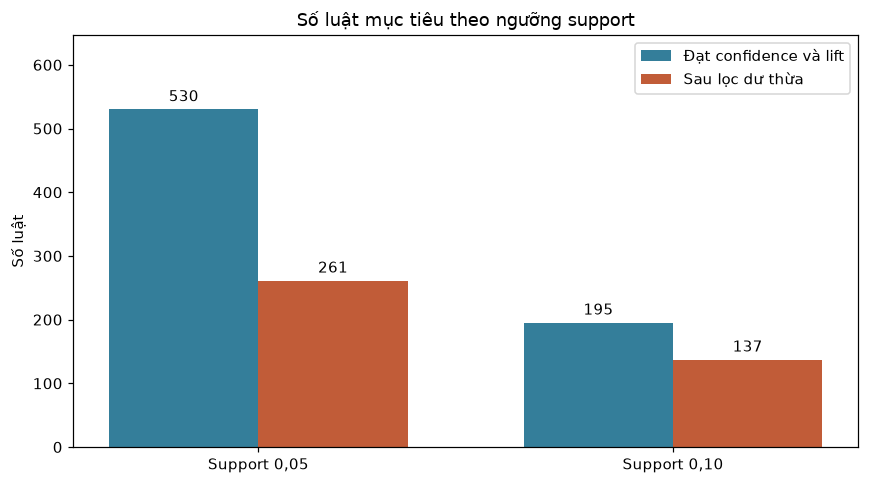

**Nhận xét:** Tăng support giữ các tổ hợp phổ biến hơn. Không diễn giải luật còn lại là đã được kiểm chứng trên khách hàng mới.

In [7]:
itemsets_10, target_10, seconds_10 = mine_rules(encoded, SUPPORTS[1])
audit_10 = mark_rules(audit_counts(target_10))
selected_10 = audit_10.loc[audit_10["selected"]].copy()
assert set(audit_10["rule_key"]) == set(audit_05.loc[audit_05["support"] >= .10 - 1e-12, "rule_key"])
common = audit_05.merge(audit_10, on="rule_key", suffixes=("_05", "_10"))
for metric in ["support", "confidence", "lift"]:
    assert np.allclose(common[metric+"_05"], common[metric+"_10"])
sensitivity = pd.DataFrame([
    {"min_support": s, "n_itemsets": len(items), "n_target_rules": len(audit),
     "n_meeting_thresholds": int(audit["meets_thresholds"].sum()),
     "n_selected": int(audit["selected"].sum()), "seconds": elapsed}
    for s, items, audit, elapsed in [
        (.05, itemsets_05, audit_05, seconds_05), (.10, itemsets_10, audit_10, seconds_10)]
])
display(sensitivity)
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
ax.bar(x-.18, sensitivity["n_meeting_thresholds"], .36, label="Đạt confidence và lift", color="#347E9A")
ax.bar(x+.18, sensitivity["n_selected"], .36, label="Sau lọc dư thừa", color="#C15C38")
ax.set_xticks(x, ["Support 0,05", "Support 0,10"])
ax.set(ylabel="Số luật", title="Số luật mục tiêu theo ngưỡng support")
ax.legend()
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set_ylim(0, max(1, sensitivity["n_meeting_thresholds"].max())*1.22)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_apriori_support_sensitivity.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Nhận xét:** Tăng support giữ các tổ hợp phổ biến hơn. "
                 "Không diễn giải luật còn lại là đã được kiểm chứng trên khách hàng mới."))

## 7. Lưu bảng luật và kiểm tra bàn giao

Lưu hai mức support riêng, mỗi mức gồm:
- tập mục phổ biến;
- mọi luật mục tiêu đạt support, kể cả chưa đạt confidence/lift, kèm cờ lọc;
- luật đạt tất cả ngưỡng trước lọc dư thừa;
- luật được giữ để xem xét diễn giải.

Các tập mục lưu dạng chuỗi JSON sắp xếp để Notebook 3 đọc chính xác, không dùng eval. Tập khách của các luật có thể chồng lấn: không cộng số khách giữa các luật để suy ra tổng người cần chăm sóc.

In [8]:
def export_rules(frame, filename):
    export = frame.copy()
    for col in ["antecedents", "consequents"]:
        export[col] = export[col].map(lambda s: json.dumps(sorted(s), ensure_ascii=False))
    export.to_csv(TABLE_DIR / filename, index=False, encoding="utf-8-sig")

for suffix, itemsets, audit in [("05", itemsets_05, audit_05), ("10", itemsets_10, audit_10)]:
    export_items = itemsets.copy()
    export_items["itemsets"] = export_items["itemsets"].map(lambda s: json.dumps(sorted(s), ensure_ascii=False))
    export_items.to_csv(TABLE_DIR / f"apriori_itemsets_support_{suffix}.csv", index=False, encoding="utf-8-sig")
    export_rules(audit, f"apriori_target_all_support_{suffix}.csv")
    export_rules(audit.loc[audit["meets_thresholds"]], f"apriori_qualified_support_{suffix}.csv")
    export_rules(audit.loc[audit["selected"]], f"apriori_selected_support_{suffix}.csv")
    assert audit["consequents"].map(lambda s: s == frozenset({"Churn=Yes"})).all()
    assert audit["antecedent_length"].between(1, 3).all()
    assert audit["antecedents"].map(lambda s: not any(x.startswith("Churn=") for x in s)).all()
    saved = pd.read_csv(TABLE_DIR / f"apriori_target_all_support_{suffix}.csv")
    assert len(saved) == len(audit)
    assert np.allclose(saved["confidence"], audit["confidence"])
sensitivity.to_csv(TABLE_DIR / "apriori_support_sensitivity.csv", index=False, encoding="utf-8-sig")
manifest = {
    "clean_sha256": metadata["clean_sha256"], "rows": N,
    "n_input_variables": 14, "transaction_columns": list(transactions.columns),
    "n_items": len(encoded.columns), "base_churn_rate": float(base_rate),
    "supports": SUPPORTS, "min_confidence": MIN_CONFIDENCE, "min_lift": MIN_LIFT,
    "max_antecedents": MAX_ANTECEDENTS, "max_itemset_length": 4,
    "redundancy_confidence_delta": REDUNDANCY_DELTA,
    "binning": binning, "mlxtend": mlxtend.__version__,
    "python": platform.python_version(), "pandas": pd.__version__,
    "sensitivity": sensitivity.to_dict(orient="records"),
    "interpretation": "Descriptive associations on full dataset; not causal or predictive validation",
}
(DATA_DIR / "apriori_run_metadata.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
assert hashlib.sha256(clean_path.read_bytes()).hexdigest() == metadata["clean_sha256"]
print("Đã kiểm tra: mốc nhóm, one-hot, ví dụ nhỏ, mọi luật mục tiêu bằng đếm trực tiếp,")
print("quy tắc dư thừa, độ nhạy support và đọc lại bảng xuất.")
print("Bảng luật:", TABLE_DIR)

Đã kiểm tra: mốc nhóm, one-hot, ví dụ nhỏ, mọi luật mục tiêu bằng đếm trực tiếp,
quy tắc dư thừa, độ nhạy support và đọc lại bảng xuất.
Bảng luật: D:\vu\hoctap\Telco-Churn-Apriori\reports\apriori\tables


## 8. Ôn bảo vệ và bước tiếp theo

1. **Vì sao Apriori?** Tìm tổ hợp mục thường xuất hiện cùng nhau, phù hợp mục tiêu luật dễ giải thích. Không bảo đảm đây là thuật toán nhanh nhất.
2. **Vì sao support 0,05?** Yêu cầu ít nhất khoảng 5% khách có cả tiền đề và churn; trên 7.043 khách tương ứng tối thiểu 353 khách. So sánh thêm 0,10 để thấy ảnh hưởng của ngưỡng.
3. **Confidence có phải accuracy?** Không; đó là tỷ lệ churn trong nhóm thỏa tiền đề trên tập dữ liệu đang khai phá.
4. **Lift 1,5 nghĩa là gì?** Tỷ lệ churn trong nhóm bằng 1,5 lần tỷ lệ churn chung, không phải tăng 50 điểm phần trăm.
5. **Vì sao không chỉ lấy khách churn?** Cần tỷ lệ nền từ cả hai nhóm; chỉ lấy khách churn sẽ làm mất ý nghĩa so sánh.
6. **Vì sao không chọn luật dài nhất?** Luật dài có thể chỉ thêm thông tin lặp và khó giải thích; cần xem số khách và mức cải thiện so với luật ngắn.
7. **Có kết luận nguyên nhân không?** Không. Ngưỡng không thay thế kiểm định thống kê; các nhóm chồng lấn và cùng dữ liệu đã dùng để tìm luật.

**Notebook 3 sẽ làm:** chọn khoảng 5–8 luật khác nhau về ý nghĩa (nếu có đủ), viết nhận xét có số liệu và đề xuất cần kiểm chứng. Bảng head ở trên chỉ là xếp hạng số học, chưa phải lựa chọn cuối cho báo cáo.